In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## scaling-law

**Figure 2: Test loss of Transformer language models on WebText2 against model size.** Both axes are log scale, markers are models trained to near convergence, and the dashed line is the power-law fit. Loss falls smoothly from 5.95 to 2.34 nats per token as non-embedding parameters grow from 6K to 1.5B, following L = (N / 8.8·10¹³)^−0.076 with no sign of deviation at the largest models.

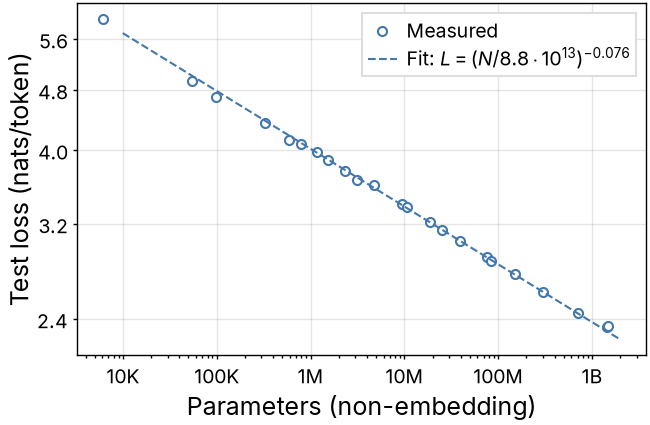

In [2]:
with open("../scaling-law.json") as f:
    data = json.load(f)

params = np.array(data["non_embedding_parameters"])
loss = np.array(data["test_loss"])
n_c, alpha = data["fit"]["N_c"], data["fit"]["alpha_N"]
n_fit = np.geomspace(*data["fit"]["plotted_N_range"], 200)

fig, ax = plt.subplots(figsize=(3.25, 2))
ax.plot(params, loss, "o", color=colors["series-1"], label="Measured")
ax.plot(n_fit, (n_fit / n_c) ** -alpha, linestyle="--", linewidth=paper.dashed_width, color=colors["series-1"],
        label=f"Fit: $L = (N / 8.8 \\cdot 10^{{13}})^{{-{alpha}}}$")

ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks([1e4, 1e5, 1e6, 1e7, 1e8, 1e9], labels=["10K", "100K", "1M", "10M", "100M", "1B"])
ax.set_yticks(data["axes"]["y_ticks"], labels=[str(t) for t in data["axes"]["y_ticks"]])
ax.set_yticks([], minor=True)
ax.set_xlabel("Parameters (non-embedding)")
ax.set_ylabel("Test loss (nats/token)")
ax.legend(loc="upper right")

fit_height(fig, ax, aspect=0.618)
fig.savefig("scaling-law.pdf")
fig.savefig("scaling-law.png")
plt.show()